# Jobsheet 6.02 - Regresi Linier, Support Vector Regression, dan Multiple Linear Regression
**Nama:** Sharren Elvaretta
**Mata Kuliah:** Machine Learning

Isi notebook:
1. **Praktikum 1** - Regresi Linier (`dataset.csv`)
2. **Praktikum 2** - Support Vector Regression (`Posisi_gaji.csv`)
3. **Tugas Praktikum** - Multiple Linear Regression (`insurance.csv`)


---
# PRAKTIKUM 1: Regresi Linier
## Langkah 1: Persiapan Data


## Langkah 2: Import Library


In [1]:
# import package
import numpy as np
import pandas as pd

## Langkah 3: Baca Data


In [22]:
# upload file dari komputer (Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = list(uploaded.keys())[0]
except ImportError:
    nama_file = 'dataset.csv'   # jika dijalankan di Jupyter lokal

data = pd.read_csv(nama_file)

Saving dataset.csv to dataset.csv


## Langkah 4: Pemahaman Terhadap Data


In [23]:
# melihat beberapa data awal
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [24]:
# mengecek ukuran data
data.shape

(500, 8)

In [25]:
# informasi tentang data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [26]:
# deskripsi data
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Langkah 5: Visualisasi Data


In [27]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
print(nama_file)
print(data.columns.tolist())
data.head()

dataset.csv
['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


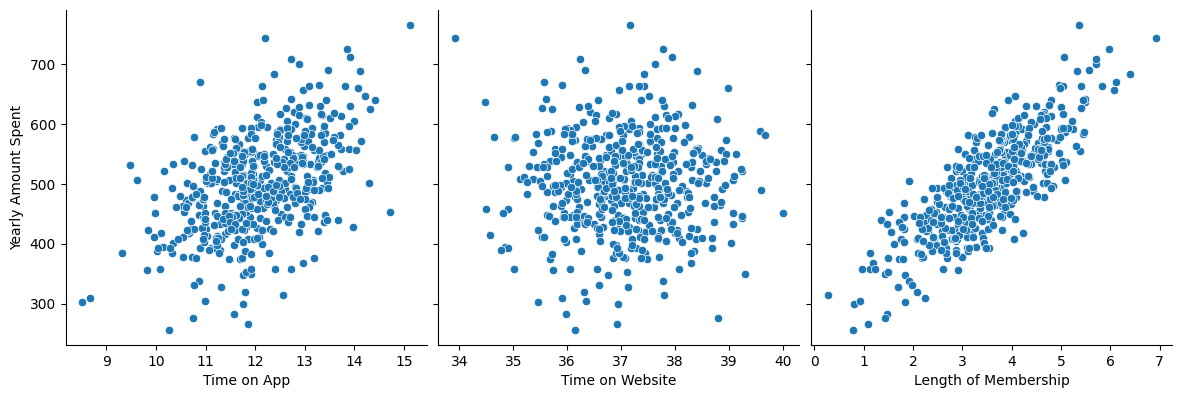

In [29]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

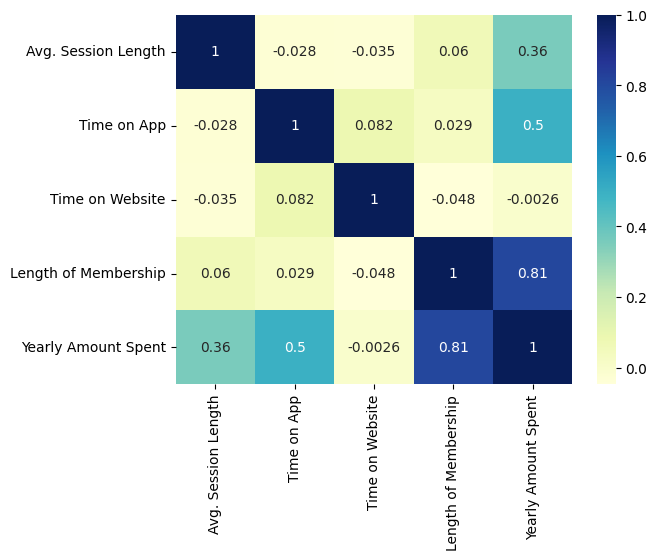

In [30]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

**Analisis:** Dari heatmap terlihat `Length of Membership` memiliki korelasi paling tinggi terhadap `Yearly Amount Spent`, sehingga variabel ini dipilih sebagai variabel bebas pada regresi linier.

## Langkah 6: Regresi Linier


In [31]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [32]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [33]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

In [34]:
# Ringkasan hasil model (nilai intercept, koefisien, R-squared, dll)
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Sun, 08 Nov 2026   Prob (F-statistic):           1.59e-85
Time:                         11:22:01   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

Intercept: 265.2482985254948
Slope    : 66.30152198546311


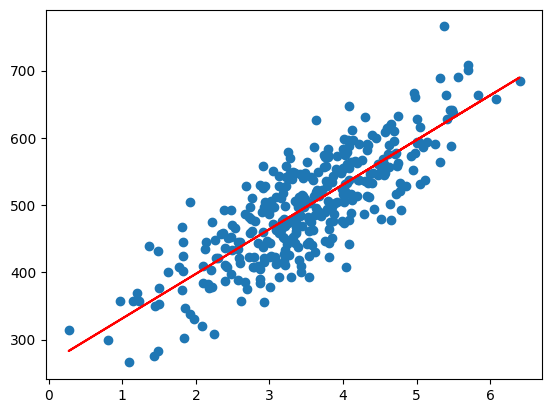

In [35]:
# Visualisasi garis regresi
intercept = lr.params['const']
slope = lr.params['Length of Membership']
print("Intercept:", intercept)
print("Slope    :", slope)

plt.scatter(X_train, y_train)
plt.plot(X_train, intercept + slope*X_train, 'r')
plt.show()

## Langkah 7: Analisis Residual


In [36]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

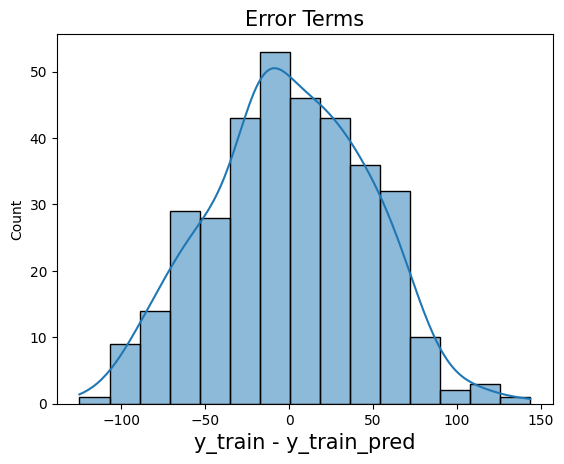

In [37]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

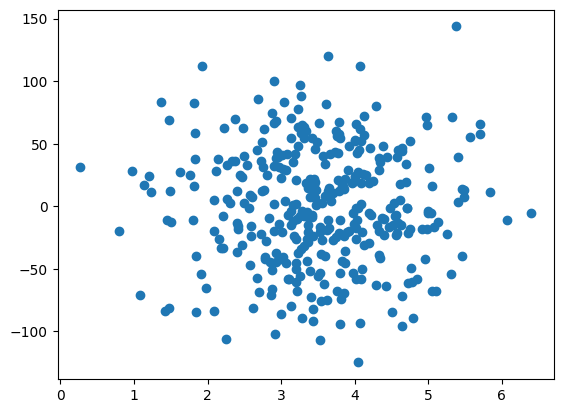

In [38]:
# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

**Analisis:** Jika histogram residual berbentuk mendekati distribusi normal dan scatter plot residual tidak membentuk pola tertentu, maka asumsi regresi linier terpenuhi.

## Langkah 8: Prediksi pada Data Uji dan Evaluasi Model


In [39]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [40]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print("R-squared data uji:", r_squared)

R-squared data uji: 0.611948913768747


## Langkah 9: Visualisasi Hasil


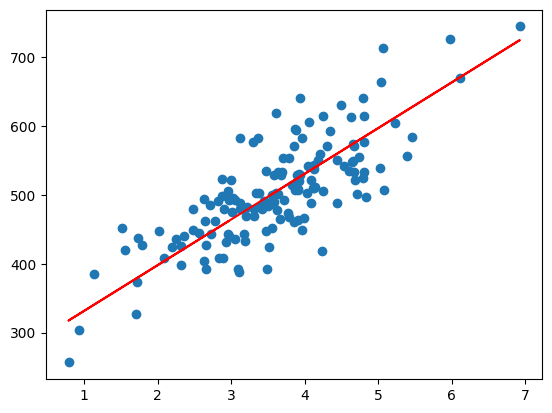

In [41]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

---
# PRAKTIKUM 2: Support Vector Regression (SVR)
## Mengimpor Library

In [42]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Mengimpor Dataset


In [43]:
# Mengimpor dataset (file CSV 'Posisi_gaji.csv')
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = list(uploaded.keys())[0]
except ImportError:
    nama_file = 'Posisi_gaji.csv'   # jika dijalankan di Jupyter lokal

dataset = pd.read_csv(nama_file)
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values
dataset

Saving Posisi_gaji.csv to Posisi_gaji.csv


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [44]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1)).ravel()

In [45]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

SVR()

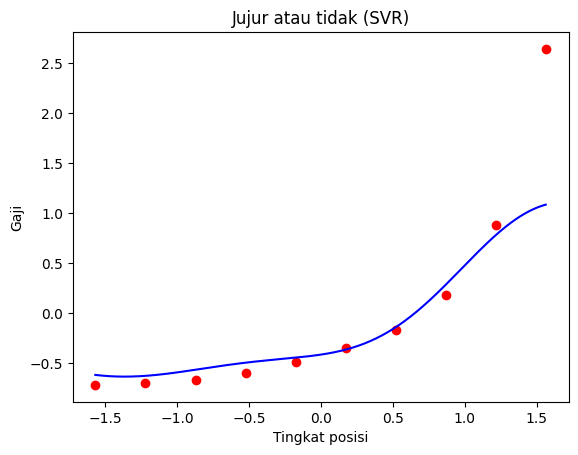

In [46]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

## Prediksi Hasil
Prediksi gaji untuk tingkat posisi 6.5: skalakan input dengan `sc_X.transform`, prediksi dengan SVR, lalu kembalikan ke skala asli dengan `sc_y.inverse_transform`.

In [47]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

## Menampilkan Hasil

In [48]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


## Validasi Hasil
Output yang diharapkan sesuai jobsheet adalah prediksi gaji untuk tingkat posisi 6.5 sekitar **170370.02**. Grafik menunjukkan titik merah (data asli) dan garis biru (prediksi SVR) yang mengikuti pola non-linear hubungan antara tingkat posisi dan gaji.

## Evaluasi Model SVR
Evaluasi model meliputi MAE, MSE, RMSE, dan R-squared.

In [49]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


---
# TUGAS PRAKTIKUM: Multiple Linear Regression
**Dataset:** Medical Cost Personal Datasets (`insurance.csv`)

Membuat model *multiple linear regression* untuk memprediksi biaya medis personal (`charges`).

## Langkah 1: Import Library dan Baca Data
Upload file `insurance.csv` dari komputer.

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
# upload file dari komputer (Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = list(uploaded.keys())[0]
except ImportError:
    nama_file = 'insurance.csv'   # jika dijalankan di Jupyter lokal

data = pd.read_csv(nama_file)

Saving insurance.csv to insurance (2).csv


## Langkah 2: Pemahaman Terhadap Data

In [52]:
# melihat beberapa data awal
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [53]:
# mengecek ukuran data
data.shape

(1338, 7)

In [54]:
# informasi tentang data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [55]:
# deskripsi data
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [56]:
# mengecek missing value
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


## Langkah 3: Visualisasi Data

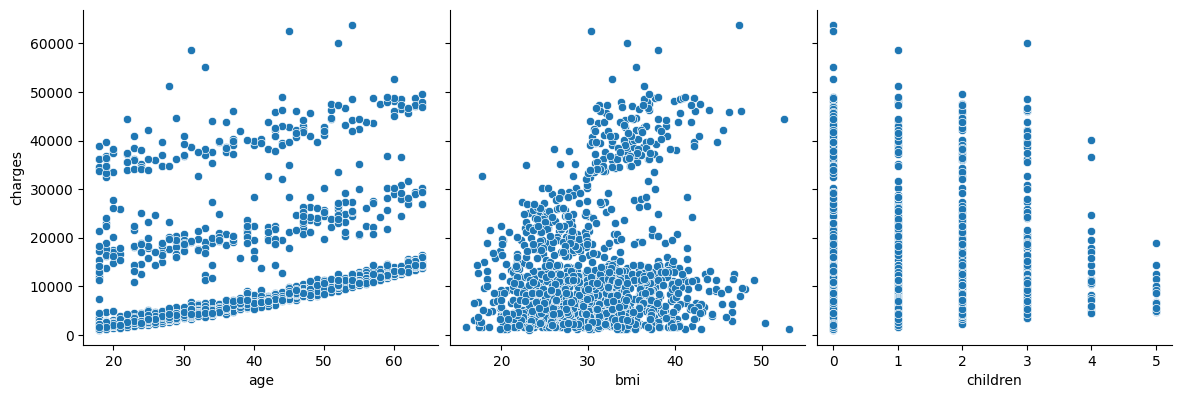

In [57]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['age', 'bmi', 'children'],
             y_vars='charges', height=4, aspect=1, kind='scatter')
plt.show()

In [58]:
# mengubah variabel kategorikal menjadi numerik
data_encoded = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
data_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


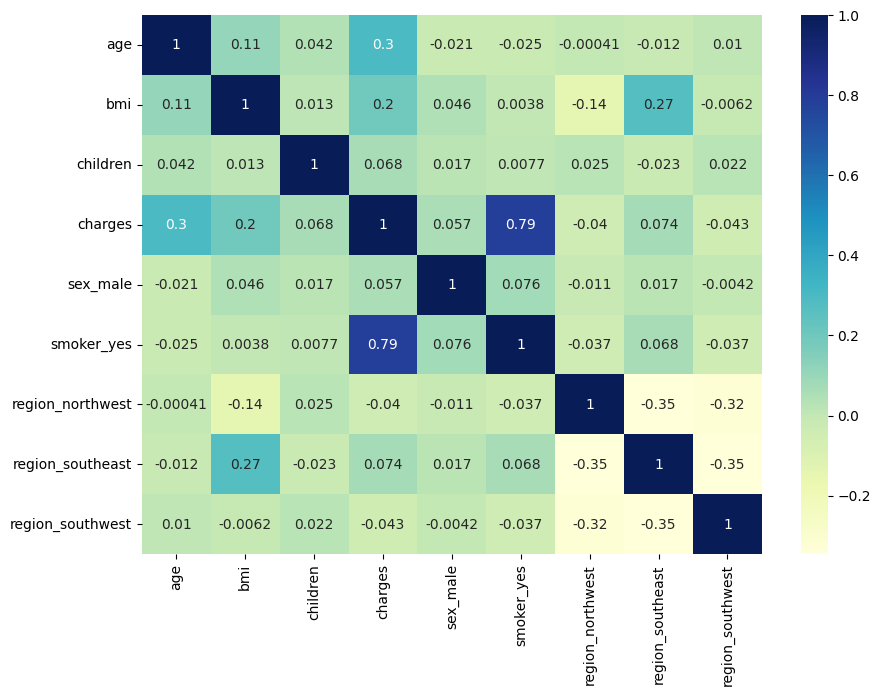

In [59]:
# visualisasi korelasi dengan heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(data_encoded.corr(), cmap="YlGnBu", annot=True)
plt.show()

## Langkah 4: Identifikasi Variabel Bebas (X) dan Target (y)
- **Variabel target (y):** `charges` (biaya medis personal)
- **Variabel bebas (X):** `age`, `bmi`, `children`, `sex_male`, `smoker_yes`, `region_northwest`, `region_southeast`, `region_southwest`

In [60]:
X = data_encoded.drop('charges', axis=1)
y = data_encoded['charges']

print(X.columns.tolist())

['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## Langkah 5: Pembagian Data Latih dan Data Uji (7:3)

In [61]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)

Data latih : (936, 8)
Data uji   : (402, 8)


## Langkah 6: Feature Scaling


In [62]:
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)

## Langkah 7: Membuat dan Melatih Model


In [63]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

LinearRegression()

In [64]:
# Intercept dan koefisien model
print("Intercept:", lr.intercept_)
pd.DataFrame({'Fitur': X.columns, 'Koefisien': lr.coef_})

Intercept: 13169.226679668802


,Fitur,Koefisien
0,age,3658.910679
1,bmi,1798.523024
2,children,569.495641
3,sex_male,-0.031034
4,smoker_yes,9494.708299
5,region_northwest,-324.738293
6,region_southeast,-423.629730
7,region_southwest,-686.507368


## Langkah 8: Prediksi pada Data Uji

In [65]:
y_test_pred = lr.predict(X_test_scaled)

hasil = pd.DataFrame({'Aktual': y_test.values, 'Prediksi': y_test_pred})
hasil.head()

,Aktual,Prediksi
0,1826.84300,4085.112362
1,20177.67113,4331.248681
2,7421.19455,8435.083234
3,1877.92940,3113.711050
4,15518.18025,25704.594920


## Langkah 9: Evaluasi Model


In [66]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r_squared = r2_score(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)

print("R-squared:", r_squared)
print("MSE:", mse)
print("MAE:", mae)

R-squared: 0.7772310511733103
MSE: 32345536.74852545
MAE: 3943.2377039473017


## Langkah 10: Visualisasi Hasil


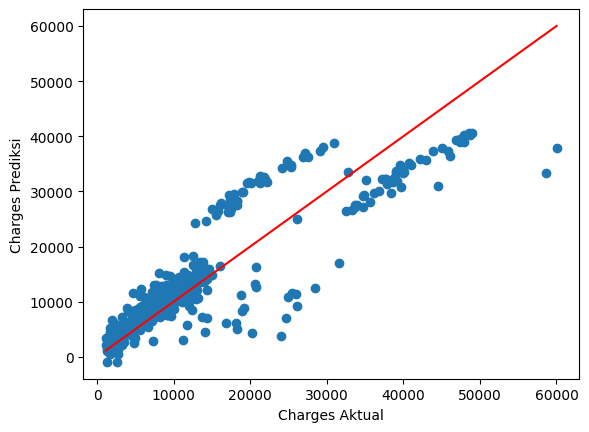

In [67]:
plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r')
plt.xlabel('Charges Aktual')
plt.ylabel('Charges Prediksi')
plt.show()

## Kesimpulan
- **Praktikum 1:** Regresi linier dengan `Length of Membership` sebagai variabel bebas dapat memprediksi `Yearly Amount Spent`, dan hasilnya dievaluasi dengan R-squared pada data uji.
- **Praktikum 2:** Model SVR dengan kernel RBF mampu menangkap hubungan non-linear antara tingkat posisi dan gaji, dengan prediksi gaji untuk posisi 6.5 sekitar 170370.
- **Tugas:** Model multiple linear regression pada data insurance dievaluasi menggunakan R-squared, MSE, dan MAE. Dari koefisien model, `smoker_yes` umumnya menjadi fitur paling berpengaruh terhadap biaya medis, diikuti `age` dan `bmi`.